# 30. 기후 취약 상권 지수와 피해 규모(Q2)

상권 단위는 지역×업종(팀 결정). 판정 방식은 복합 지수(팀 결정). 틀은 IPCC AR5/AR6의 위험 = 위해 × 노출 × 취약성(민감도, 적응능력)을 그대로 쓴다.

| 축 | 뜻 | 지표(출처) |
|---|---|---|
| 민감도 S_e | 이벤트 e가 있는 날 매출이 얼마나 줄어드는가 | 20번 회귀의 시리즈별 계수(경험적 베이즈로 지역 평균 쪽으로 축소), 감소분만(≥0) |
| 노출 E_e | 이벤트가 생기는 시간에 장사를 얼마나 하는가 | 시간대별 매출 비중(카드) × 이벤트의 시간대 분포(기상). 폭염·열대야는 60대+ 고객 비중 × 지역 유동인구 60대+ 비중(SK)을 더함 |
| 적응능력 A | 손실을 메우거나 버틸 힘 | 비 다음 날 반등 계수(+), 소상공인 중심 업종 여부(−), 외지인 결제 비중(−) |

민감도는 증거가 있을 때만 센다: 시리즈 자체 추정이 유의하게 음수(p<0.10)이거나, 그 지역·이벤트의 평균 효과가 유의하게 음수(z<−1.96)일 때만 축소 계수를 쓰고, 아니면 0으로 둔다(열대야처럼 지역 평균이 0 근처인 이벤트에서 모든 업종에 작은 손실이 퍼지는 것을 막는다).
정규화는 지표마다 상위 5% 값을 잘라낸(윈저화) 뒤 최소-최대(0~1). 결합은 가중 기하평균 `V_e = S_e^0.5 × E_e^0.25 × (1−A)^0.25` (OECD/JRC 핸드북의 비보상적 결합. 민감도가 0이면 취약도도 0). 가중치는 민감도가 직접 측정값이라 절반, 나머지는 구조 변수라 1/4씩 둔다. 가중치·결합 방식을 바꿨을 때 순위가 얼마나 흔들리는지 8절에서 확인한다.

피해 규모(위험) = 2025년 7~12월 실제 이벤트일 매출 × 감소율로 집계한 손실액. 이벤트 하루당 평균 손실은 40번(예측·우선순위)에서 쓴다.

범위(팀 결정 2026-10-11): 민감도는 대면 업종 전체로 추정하되, 취약 판정·등급·손실 집계·순위는 소상공인 중심 업종(`industry_map`의 small_biz=1)만으로 한다. 골프장·놀이동산·대형마트·쇼핑몰·백화점·호텔 같은 대형 업종은 "상권 앵커" 맥락으로 따로 표만 둔다.

출력: `outputs/tables/v_index.csv`(시리즈별 모든 지표), `v_summary_*.csv`, 그림 `v*.png`

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.stats import spearmanr

sys.path.insert(0, str(Path.cwd()))
from common import (FIG, TAB, REGIONS, REGION_NAME, TIME_BANDS, TB_NAME, AGE_GROUPS, FACE_GROUPS, load)
from analysis import (RC, SURFACE, INK, INK2, MUTED, GRID, AXIS, WASH, REGION_COLOR, EVENT_COLOR, finish)

FIG.mkdir(parents=True, exist_ok=True); TAB.mkdir(parents=True, exist_ok=True)
plt.rcParams.update(RC)
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 80); pd.set_option("display.max_rows", 200)

EVS = ["heat_day", "tropical", "rain_biz10"]
EV_NAME = {"heat_day": "폭염", "tropical": "열대야", "rain_biz10": "호우"}
W_S, W_E, W_A = 0.5, 0.25, 0.25

prof = load("industry_profile")
day = load("model_panel_day"); day = day[day.in_scope == 1].copy()
w = load("weather_daily").query("'2025-07-01' <= date <= '2025-12-31'").copy()
wh = load("weather_hourly").query("'2025-07-01' <= date <= '2025-12-31'").copy()
sk = load("sk_region").set_index("region")
sens = pd.read_csv(TAB / "s_day_series.csv", encoding="utf-8-sig")
keys = ["region", "industry"]
series = prof[prof.set_index(keys).index.isin(day.set_index(keys).index.unique())][keys + ["group", "small_biz", "discretionary", "outdoor",
          "sales_total", "sales_day", "cnt_day", "ticket", "share_nonlocal", "share_age_60대+", "cv_workday"] + [f"share_tb_{t}" for t in TIME_BANDS]].copy()
series["face"] = series.group.isin(FACE_GROUPS).astype(int)
series["sb"] = ((series.face == 1) & (series.small_biz == 1)).astype(int)  # 판정·손실·순위 범위: 대면 + 소상공인 중심
print("시리즈", len(series), "대면소비", series.face.sum(), "그중 소상공인 중심", series.sb.sum())

시리즈 141 대면소비 101 그중 소상공인 중심 82


## 1. 민감도 S: 시리즈별 계수의 경험적 베이즈 축소

시리즈마다 이벤트 수가 적어(열대야 춘천 6일) 계수 추정치가 흔들린다. 지역×이벤트 안에서 참값 분산 τ²을 추정해 `β_eb = μ + τ²/(τ²+se²)·(β−μ)`로 축소한다. 표준오차가 큰 시리즈일수록 지역 평균 μ 쪽으로 당겨진다.

In [2]:
def eb_shrink(df, by):
    out = []
    for key, g in df.groupby(by):
        wgt = 1 / g.se ** 2
        mu = np.average(g.coef, weights=wgt)
        tau2 = max(0.0, g.coef.var(ddof=1) - (g.se ** 2).mean()) if len(g) > 2 else 0.0
        shrink = tau2 / (tau2 + g.se ** 2)
        out.append(g.assign(mu=mu, tau=np.sqrt(tau2), shrink=shrink, coef_eb=mu + shrink * (g.coef - mu)))
    return pd.concat(out)

sub = sens[sens["var"].isin(EVS + ["rain_biz10_lag1"])].copy()
eb = eb_shrink(sub, ["region", "var"])
print(eb.groupby(["region", "var"])[["mu", "tau", "shrink"]].mean().round(3))
S = eb.pivot(index=keys, columns="var", values="coef_eb")
S_raw = eb.pivot(index=keys, columns="var", values="coef")
S_p = eb.pivot(index=keys, columns="var", values="p")
pooled_z = eb.groupby(["region", "var"]).apply(lambda g: np.average(g.coef, weights=1 / g.se ** 2) / np.sqrt(1 / np.sum(1 / g.se ** 2)), include_groups=False)
print("지역 평균 효과 z값:"); print(pooled_z.unstack("var").round(2))
idx = series.set_index(keys).index
tabS = pd.DataFrame(index=idx)
for ev in EVS:
    region_sig = pd.Series(idx.get_level_values("region"), index=idx).map(pooled_z.xs(ev, level="var")) < -1.96
    own_sig = (S_raw[ev].reindex(idx) < 0) & (S_p[ev].reindex(idx) < 0.10)
    tabS[f"evid_{ev}"] = (region_sig | own_sig).astype(int)
    tabS[f"beta_eb_{ev}"] = S[ev].reindex(idx)
    tabS[f"beta_{ev}"] = S[ev].reindex(idx).where(tabS[f"evid_{ev}"] == 1, 0.0)  # 증거가 있을 때만 쓰는 계수
    tabS[f"beta_raw_{ev}"] = S_raw[ev].reindex(idx)
    tabS[f"p_{ev}"] = S_p[ev].reindex(idx)
    tabS[f"S_{ev}"] = (1 - np.exp(tabS[f"beta_{ev}"].fillna(0))).clip(lower=0) * 100  # 감소율(%), 감소만
tabS["rebound"] = S["rain_biz10_lag1"].reindex(idx).fillna(0)
print("증거 있는 시리즈 수:"); print(tabS.groupby(level="region")[[f"evid_{ev}" for ev in EVS]].sum())
tabS[[f"S_{ev}" for ev in EVS]].describe().round(1)

                              mu    tau  shrink
region    var                                  
chuncheon heat_day         0.025  0.049   0.350
          rain_biz10      -0.090  0.220   0.775
          rain_biz10_lag1 -0.005  0.128   0.660
          tropical         0.017  0.000   0.000
gangnam   heat_day         0.028  0.000   0.000
          rain_biz10      -0.048  0.069   0.451
          rain_biz10_lag1 -0.002  0.085   0.583
          tropical        -0.008  0.054   0.409
지역 평균 효과 z값:
var        heat_day  rain_biz10  rain_biz10_lag1  tropical
region                                                    
chuncheon      5.27      -15.97            -1.06      3.08
gangnam        6.65       -9.20            -0.55     -1.85
증거 있는 시리즈 수:
           evid_heat_day  evid_tropical  evid_rain_biz10
region                                                  
chuncheon              4              5               64
gangnam                5              8               77


,S_heat_day,S_tropical,S_rain_biz10
count,141.0,141.0,141.0
mean,0.1,0.3,8.4
std,0.6,1.2,7.8
min,0.0,0.0,0.0
25%,0.0,0.0,3.1
50%,0.0,0.0,6.7
75%,0.0,0.0,11.4
max,5.9,6.9,49.9


## 2. 노출 E: 이벤트가 생기는 시간에 장사를 얼마나 하는가

- 시간 노출 = Σ_시간대 (시리즈의 시간대 매출 비중 × 그 지역에서 이벤트가 그 시간대에 생기는 비중). 폭염은 체감 33℃ 이상인 시간의 분포, 호우는 비 온 날 강수량의 시간대 분포. 열대야는 저녁(18~24시) 매출 비중.
- 고령 고객 노출(폭염·열대야만) = 시리즈의 60대+ 결제 비중 × 지역 유동인구 60대+ 비중(SK). 두 값을 정규화해 평균한다.

In [3]:
heat_h = wh[wh.heat_hr == 1].groupby(["region", "tb"]).size().unstack("tb").reindex(columns=TIME_BANDS, fill_value=0)
rainy = w.loc[w.rain_biz10 == 1, ["region", "date"]]
rain_h = wh.merge(rainy, on=["region", "date"]).groupby(["region", "tb"]).rn.sum().unstack("tb").reindex(columns=TIME_BANDS, fill_value=0)
share = lambda m: m.div(m.sum(axis=1), axis=0)
haz_tb = {"heat_day": share(heat_h), "rain_biz10": share(rain_h)}
haz_tb["tropical"] = pd.DataFrame({t: [1.0 if t == "18_23" else 0.0] * 2 for t in TIME_BANDS}, index=REGIONS)
tabE = pd.DataFrame(index=idx)
st = series.set_index(keys)
for ev in EVS:
    tabE[f"Etime_{ev}"] = sum(st[f"share_tb_{t}"] * st.index.get_level_values("region").map(haz_tb[ev][t]).values for t in TIME_BANDS)
tabE["Eage"] = st["share_age_60대+"] * st.index.get_level_values("region").map(sk["share_age_60p"]).values
def mm(s, cap=0.95):
    """윈저화(상위 5% 자름) 뒤 최소-최대 정규화."""
    c = s.quantile(cap)
    s2 = s.clip(upper=c)
    return (s2 - s2.min()) / (s2.max() - s2.min()) if s2.max() > s2.min() else s2 * 0
for ev in EVS:
    tabE[f"E_{ev}"] = (mm(tabE[f"Etime_{ev}"]) + mm(tabE["Eage"])) / 2 if ev != "rain_biz10" else mm(tabE[f"Etime_{ev}"])
print("이벤트의 시간대 분포(위해 쪽 입력):")
pd.concat({"폭염 시간": haz_tb["heat_day"], "강수량(비 10mm+ 날)": haz_tb["rain_biz10"]}).round(2)

이벤트의 시간대 분포(위해 쪽 입력):


tb                        00_05  06_11  12_17  18_23
               region                               
폭염 시간          chuncheon   0.00   0.10   0.82   0.08
               gangnam     0.00   0.20   0.69   0.11
강수량(비 10mm+ 날) chuncheon   0.16   0.34   0.24   0.25
               gangnam     0.17   0.36   0.24   0.24

## 3. 적응능력 A

- 반등: 비 다음 날 계수(축소값). 양수면 미뤄진 소비가 돌아온다는 뜻.
- 소상공인 중심 업종(industry_map의 small_biz)은 1, 아니면 0. 소상공인은 손실을 버틸 여력이 작다(JPMC 연구: 소상공인 현금 보유 약 2주).
- 외지인 결제 비중: 방문객 수요는 날씨에 날아가면 돌아오지 않는다(지역민은 다음 날 올 수 있다). 20번의 거주지별 추정과 함께 해석.
A = 세 지표 정규화 평균(높을수록 적응력이 큼).

In [4]:
tabA = pd.DataFrame(index=idx)
tabA["A_rebound"] = mm(tabS["rebound"])
tabA["A_not_small"] = 1 - st["small_biz"]
tabA["A_local"] = 1 - mm(st["share_nonlocal"].fillna(st["share_nonlocal"].median()))
tabA["A"] = tabA[["A_rebound", "A_not_small", "A_local"]].mean(axis=1)
tabA.describe().round(2)

,A_rebound,A_not_small,A_local,A
count,141.00,141.00,141.00,141.00
mean,0.61,0.34,0.62,0.52
std,0.24,0.48,0.27,0.18
min,0.00,0.00,0.00,0.19
25%,0.45,0.00,0.46,0.38
50%,0.62,0.00,0.65,0.48
75%,0.80,1.00,0.85,0.63
max,1.00,1.00,1.00,0.95


## 4. 결합: 이벤트별 취약 지수 V_e 와 종합 V

In [5]:
V = pd.DataFrame(index=idx)
for ev in EVS:
    s_, e_, a_ = mm(tabS[f"S_{ev}"]), tabE[f"E_{ev}"], 1 - tabA["A"]
    V[f"V_{ev}"] = (s_ ** W_S) * (e_.clip(lower=0.02) ** W_E) * (a_.clip(lower=0.02) ** W_A)
V["V"] = V[[f"V_{ev}" for ev in EVS]].mean(axis=1)
# 등급: 대면소비 시리즈 안에서 상위 25% = 취약, 상위 10% = 매우 취약
full = pd.concat([series.set_index(keys), tabS, tabE, tabA, V], axis=1)
# 등급: 소상공인 중심 대면 업종 안에서 상위 25% = 취약, 상위 10% = 매우 취약. 대형 업종은 판정에서 제외
for col in ["V"] + [f"V_{ev}" for ev in EVS]:
    q = full.loc[full.sb == 1, col].quantile([0.75, 0.9])
    full[f"grade_{col}"] = np.select([full[col] >= q[0.9], full[col] >= q[0.75]], ["매우 취약", "취약"], "보통")
    full.loc[full[col] <= 0, f"grade_{col}"] = "해당 없음"
    full.loc[full.sb == 0, f"grade_{col}"] = "대형(판정 제외)"
full["rank_V"] = full.V.where(full.sb == 1).rank(ascending=False)
print(full[full.sb == 1].groupby(["region", "grade_V"]).size().unstack(fill_value=0))
full[full.sb == 1].sort_values("V", ascending=False)[["group", "V", "V_heat_day", "V_tropical", "V_rain_biz10", "S_heat_day", "S_tropical", "S_rain_biz10", "A", "grade_V"]].head(25).round(2)

grade_V    매우 취약  보통  취약  해당 없음
region                         
chuncheon      7  18   9      6
gangnam        2  37   3      0


group     V  V_heat_day  V_tropical  V_rain_biz10  S_heat_day  S_tropical  S_rain_biz10     A grade_V
region    industry                                                                                                               
gangnam   화원              생활·기타소매  0.35         0.0        0.73          0.33        0.00        4.44          3.36  0.36   매우 취약
          싸우나/목욕탕           개인서비스  0.32         0.0        0.74          0.21        0.00        5.02          1.42  0.41   매우 취약
chuncheon 화원              생활·기타소매  0.29         0.0        0.00          0.87        0.00        0.00         29.97  0.29   매우 취약
          가구              생활·기타소매  0.27         0.0        0.00          0.81        0.00        0.00         28.97  0.34   매우 취약
          인테리어/건축자재/주방기구  생활·기타소매  0.26         0.0        0.00          0.79        0.00        0.00         18.21  0.47   매우 취약
          중고품판매점          생활·기타소매  0.26         0.0        0.00          0.79        0.00        0.00         28.90  0.45   매우 취약
          애완동물            생활·기타소매  0.26         0.0        0.00          0.77        0.00        0.00         18.19  0.37   매우 취약
          완구/아동용자전거       생활·기타소매  0.25         0.0        0.00          0.76        0.00        0.00         20.67  0.45   매우 취약
          세탁소               개인서비스  0.25         0.0        0.00          0.74        2.45        0.00         27.77  0.62   매우 취약
          일식                  음식점  0.25         0.0        0.00          0.74        0.00        0.00         18.66  0.39      취약
          농수산물             식품·생필품  0.24         0.0        0.00          0.71        0.00        0.00         14.54  0.49      취약
          시계/귀금속            패션·잡화  0.23         0.0        0.00          0.70        2.02        0.00         17.73  0.51      취약
          생활잡화/수입상품점      생활·기타소매  0.23         0.0        0.00          0.70        0.00        0.00         16.57  0.45      취약
          서점              생활·기타소매  0.23         0.0        0.00          0.70        0.00        0.00         15.71  0.37      취약
          커피전문점           카페·베이커리  0.23         0.0        0.00          0.69        0.00        0.00         15.56  0.48      취약
gangnam   기타식품             식품·생필품  0.22         0.0        0.00          0.67        0.00        0.00         13.79  0.41      취약
          인테리어/건축자재/주방기구  생활·기타소매  0.22         0.0        0.00          0.66        0.00        0.00         11.42  0.39      취약
chuncheon 의복/의류             패션·잡화  0.22         0.0        0.00          0.65        0.00        0.00         16.05  0.51      취약
          안마/마사지            개인서비스  0.22         0.0        0.00          0.65        0.00        0.00         14.53  0.31      취약
gangnam   세탁소               개인서비스  0.21         0.0        0.00          0.63        0.00        0.00         12.12  0.42      취약
chuncheon 패션잡화              패션·잡화  0.21         0.0        0.00          0.62        0.00        0.00         15.84  0.62      취약
          모텔,여관,기타숙박           숙박  0.20         0.0        0.00          0.61        0.00        0.00         11.21  0.23      보통
          양식                  음식점  0.20         0.0        0.00          0.61        0.00        0.00         11.81  0.32      보통
          한식                  음식점  0.20         0.0        0.00          0.61        0.00        0.00         11.87  0.36      보통
          사무기기/문구용품       생활·기타소매  0.20         0.0        0.00          0.60        0.00        0.00         12.88  0.53      보통

## 5. 피해 규모: 2025년 7~12월 실제 이벤트일 손실액

손실 = Σ(이벤트일 매출 × (exp(−β_eb) − 1)), β_eb < 0인 시리즈만. 이벤트일 매출은 이미 줄어든 값이므로 평상시 기대 매출 = 매출/exp(β)이고, 손실 = 기대 매출 − 실제 매출.
'순효과'는 매출이 늘어난 시리즈(β > 0)까지 합친 값이다.

In [6]:
dd = day[keys + ["date", "sales", "w_heat_day", "w_tropical", "w_rain_biz10", "w_rn_biz", "w_night_min", "w_ta_max_off", "dow"]].copy()
loss_rows = []
for ev in EVS:
    b = tabS[f"beta_{ev}"].fillna(0)
    x = dd[dd[f"w_{ev}"] == 1].merge(b.rename("beta").reset_index(), on=keys)
    x["expected"] = x.sales / np.exp(x.beta)
    x["net"] = x.expected - x.sales              # +면 손실
    x["loss"] = x.net.where(x.beta < 0, 0.0)     # 감소 시리즈만
    agg = x.groupby(keys).agg(**{f"loss_{ev}": ("loss", "sum"), f"net_{ev}": ("net", "sum"),
                                 f"days_{ev}": ("date", "nunique"), f"eventsales_{ev}": ("sales", "sum")})
    loss_rows.append(agg)
L = pd.concat(loss_rows, axis=1).reindex(idx).fillna(0)
for ev in EVS:
    L[f"loss_per_day_{ev}"] = L[f"loss_{ev}"] / L[f"days_{ev}"].replace(0, np.nan)
L["loss_total"] = L[[f"loss_{ev}" for ev in EVS]].sum(axis=1)
L["net_total"] = L[[f"net_{ev}" for ev in EVS]].sum(axis=1)
L["loss_rate"] = L.loss_total / st.sales_total * 100  # 6개월 매출 대비 %
full = pd.concat([full, L], axis=1)
full["rank_loss"] = full.loss_total.where(full.sb == 1).rank(ascending=False)
summ_r = full[full.sb == 1].groupby("region").agg(손실_폭염_억=("loss_heat_day", lambda s: s.sum() / 1e8), 손실_열대야_억=("loss_tropical", lambda s: s.sum() / 1e8),
                                                   손실_호우_억=("loss_rain_biz10", lambda s: s.sum() / 1e8), 손실_합계_억=("loss_total", lambda s: s.sum() / 1e8),
                                                   순효과_억=("net_total", lambda s: s.sum() / 1e8), 매출_억=("sales_total", lambda s: s.sum() / 1e8))
summ_r["손실률_%"] = summ_r.손실_합계_억 / summ_r.매출_억 * 100
summ_r.round(1).to_csv(TAB / "v_summary_region.csv", encoding="utf-8-sig")
summ_g = full[full.sb == 1].groupby(["region", "group"]).agg(손실_합계_억=("loss_total", lambda s: s.sum() / 1e8), 손실_호우_억=("loss_rain_biz10", lambda s: s.sum() / 1e8),
                                                            손실_폭염_억=("loss_heat_day", lambda s: s.sum() / 1e8), 손실_열대야_억=("loss_tropical", lambda s: s.sum() / 1e8),
                                                            매출_억=("sales_total", lambda s: s.sum() / 1e8), 시리즈=("V", "size"))
summ_g["손실률_%"] = summ_g.손실_합계_억 / summ_g.매출_억 * 100
summ_g.round(2).to_csv(TAB / "v_summary_group.csv", encoding="utf-8-sig")
print(summ_r.round(1))
large = full[(full.face == 1) & (full.sb == 0)].sort_values("loss_total", ascending=False)[["group", "sales_total", "loss_rain_biz10", "loss_tropical", "loss_total", "loss_rate", "S_rain_biz10"]].copy()
for c in ["sales_total", "loss_rain_biz10", "loss_tropical", "loss_total"]:
    large[c] = (large[c] / 1e8).round(1)
large.round(2).to_csv(TAB / "v_summary_large.csv", encoding="utf-8-sig")
print("대형 업종(판정 제외, 상권 앵커 맥락) 손실(억원):"); print(large.round(2).to_string())
print("손실액 상위 10 시리즈(소상공인 중심, 억원):")
print((full[full.sb == 1].sort_values("loss_total", ascending=False)[["group", "loss_heat_day", "loss_tropical", "loss_rain_biz10", "loss_total", "loss_rate"]].head(10)
       .assign(**{c: lambda x, c=c: (x[c] / 1e8).round(1) for c in ["loss_heat_day", "loss_tropical", "loss_rain_biz10", "loss_total"]}).round(2)).to_string())
summ_g.round(2)

           손실_폭염_억  손실_열대야_억  손실_호우_억  손실_합계_억  순효과_억     매출_억  손실률_%
region                                                               
chuncheon      1.0       0.0     95.1     96.0   94.8   7585.2    1.3
gangnam        0.0       1.3    203.0    204.4  198.7  37127.3    0.6
대형 업종(판정 제외, 상권 앵커 맥락) 손실(억원):
                          group  sales_total  loss_rain_biz10  loss_tropical  loss_total  loss_rate  S_rain_biz10
region    industry                                                                                               
gangnam   쇼핑몰              대형유통      10154.5             17.4          131.0       148.4       1.46          1.90
          할인점/슈퍼마켓/양판점   식품·생필품      10904.8             84.4            0.0        84.4       0.77          9.00
chuncheon 실내/실외골프장       여가·스포츠        478.3             40.4            0.0        40.4       8.46         49.88
gangnam   백화점              대형유통       5288.2             26.7            0.0        26.7       0.50          6.21
chunc

손실_합계_억  손실_호우_억  손실_폭염_억  손실_열대야_억      매출_억  시리즈  손실률_%
region    group                                                             
chuncheon 개인서비스       4.42     4.34     0.08      0.00    259.45    5   1.70
          생활·기타소매    15.01    15.01     0.00      0.00    875.15   13   1.71
          숙박          0.65     0.65     0.00      0.00     50.78    1   1.28
          식품·생필품     13.19    13.19     0.00      0.00   1691.87    4   0.78
          여가·스포츠      0.64     0.64     0.00      0.00    236.16    4   0.27
          음식점        50.97    50.97     0.00      0.00   3743.39    6   1.36
          주점·유흥       1.70     0.96     0.74      0.00     83.42    1   2.04
          카페·베이커리     4.02     4.02     0.00      0.00    303.85    2   1.32
          패션·잡화       5.44     5.29     0.15      0.00    341.11    4   1.60
gangnam   개인서비스      13.75    13.11     0.00      0.65   1903.21    5   0.72
          생활·기타소매    25.64    24.96     0.00      0.69   4273.26   14   0.60
          숙박          0.03     0.03     0.00      0.00    189.35    1   0.01
          식품·생필품     17.91    17.91     0.00      0.00   3497.19    5   0.51
          여가·스포츠      7.98     7.98     0.00      0.00   1487.96    4   0.54
          음식점        92.40    92.40     0.00      0.00  14759.94    6   0.63
          주점·유흥       0.65     0.65     0.00      0.00    412.65    1   0.16
          카페·베이커리    15.30    15.30     0.00      0.00   4210.19    2   0.36
          패션·잡화      30.69    30.69     0.00      0.00   6393.52    4   0.48

## 6. 그림

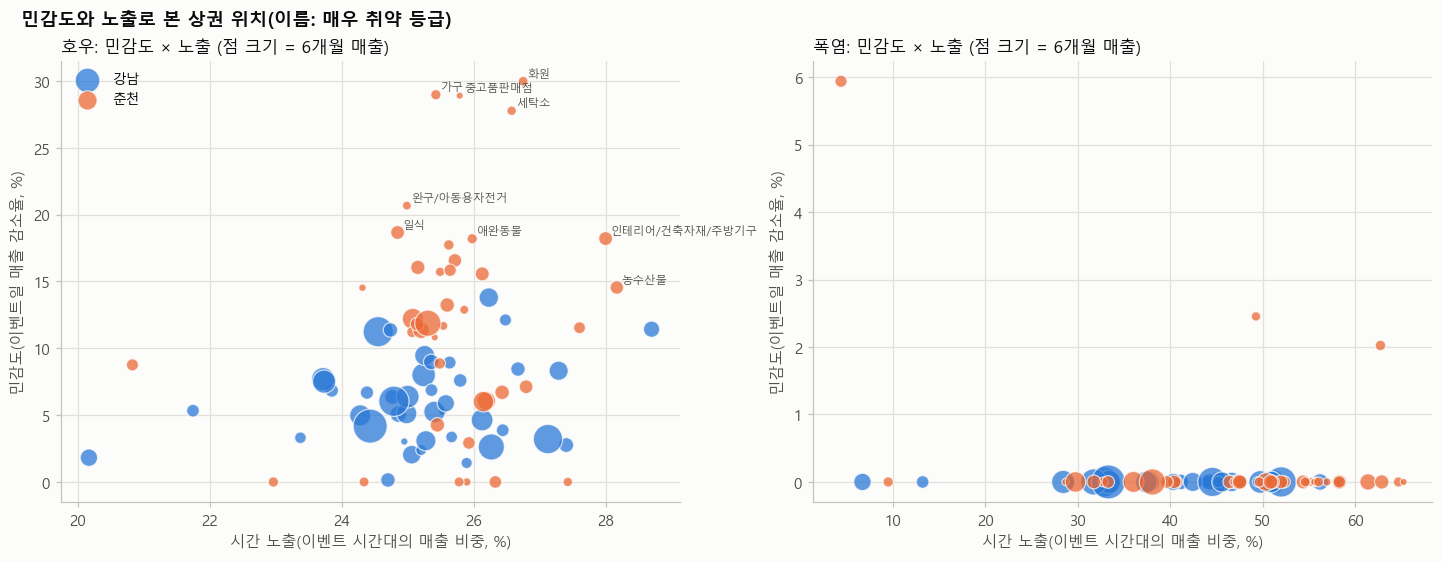

In [7]:
face = full[full.sb == 1]  # 이하 그림·목록은 소상공인 중심 업종만
# (1) 민감도 × 노출 산점도(호우), 점 크기 = 매출
fig, axes = plt.subplots(1, 2, figsize=(13, 5), layout="constrained")
for ax, ev in zip(axes, ["rain_biz10", "heat_day"]):
    for r in REGIONS:
        x = face.xs(r, level="region")
        ax.scatter(x[f"Etime_{ev}"] * 100, x[f"S_{ev}"], s=np.sqrt(x.sales_total / 1e8) * 6 + 8, color=REGION_COLOR[r], alpha=0.75,
                   edgecolors=SURFACE, linewidths=0.8, label=REGION_NAME[r])
        top = x[x[f"grade_V_{ev}"] == "매우 취약"]
        for ind, row in top.iterrows():
            ax.annotate(ind, (row[f"Etime_{ev}"] * 100, row[f"S_{ev}"]), fontsize=7.5, color=INK2, xytext=(3, 3), textcoords="offset points")
    ax.set_xlabel("시간 노출(이벤트 시간대의 매출 비중, %)"); ax.set_ylabel("민감도(이벤트일 매출 감소율, %)")
    ax.set_title(f"{EV_NAME[ev]}: 민감도 × 노출 (점 크기 = 6개월 매출)")
axes[0].legend(loc="upper left")
finish(fig, FIG, "v01_sens_exposure", "민감도와 노출로 본 상권 위치(이름: 매우 취약 등급)")
plt.show()

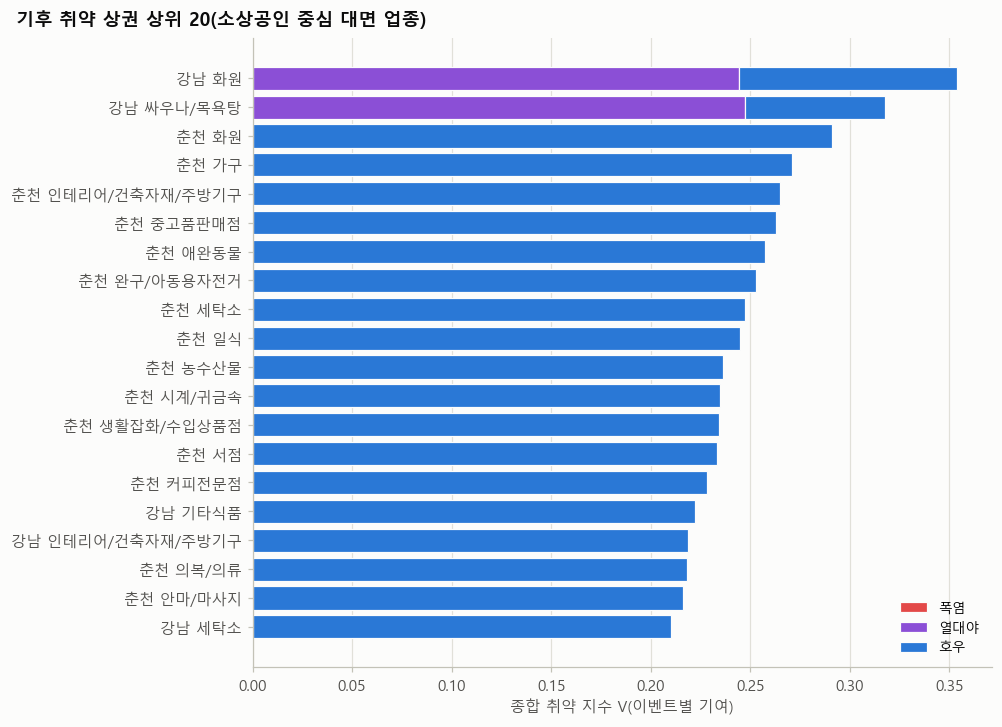

In [8]:
# (2) 종합 취약 지수 상위 20
top = face.sort_values("V", ascending=False).head(20).reset_index()
fig, ax = plt.subplots(figsize=(9, 6.5), layout="constrained")
cols = [REGION_COLOR[r] for r in top.region]
left = np.zeros(len(top))
for ev, c in zip(EVS, ["#e34948", "#8b4fd6", "#2a78d6"]):
    v = top[f"V_{ev}"].values / 3
    ax.barh(range(len(top)), v, left=left, color=c, label=EV_NAME[ev], edgecolor=SURFACE, linewidth=0.8)
    left += v
ax.set_yticks(range(len(top)), [f"{REGION_NAME[r]} {i}" for r, i in zip(top.region, top.industry)])
ax.invert_yaxis(); ax.set_xlabel("종합 취약 지수 V(이벤트별 기여)"); ax.legend(loc="lower right"); ax.grid(axis="y", visible=False)
finish(fig, FIG, "v02_top20", "기후 취약 상권 상위 20(소상공인 중심 대면 업종)")
plt.show()

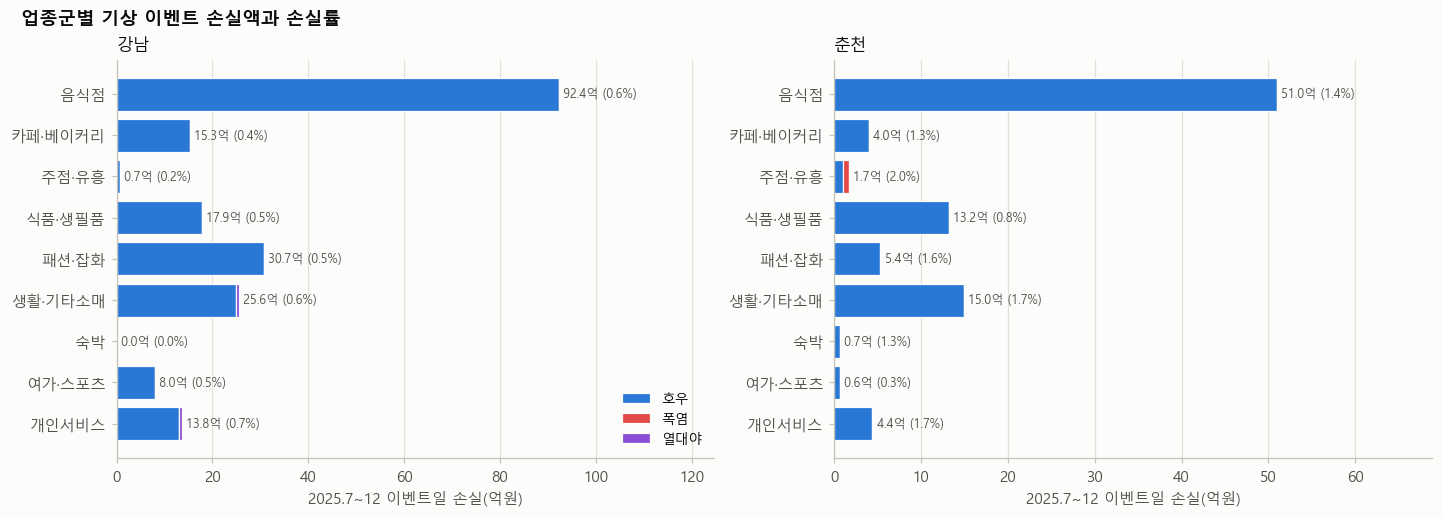

In [9]:
# (3) 업종군·지역별 손실액
g = summ_g.reset_index()
fig, axes = plt.subplots(1, 2, figsize=(13, 4.6), sharey=False, layout="constrained")
for ax, r in zip(axes, REGIONS):
    x = g[g.region == r].set_index("group").reindex(FACE_GROUPS).dropna(subset=["손실_합계_억"])
    left = np.zeros(len(x))
    for ev, c in zip(["호우", "폭염", "열대야"], ["#2a78d6", "#e34948", "#8b4fd6"]):
        v = x[f"손실_{ev}_억"].values
        ax.barh(range(len(x)), v, left=left, color=c, label=ev, edgecolor=SURFACE, linewidth=0.8); left += v
    for i, (tot, rate) in enumerate(zip(x.손실_합계_억, x["손실률_%"])):
        ax.text(tot, i, f" {tot:.1f}억 ({rate:.1f}%)", va="center", fontsize=8, color=INK2)
    ax.set_yticks(range(len(x)), x.index); ax.invert_yaxis(); ax.set_title(REGION_NAME[r]); ax.set_xlabel("2025.7~12 이벤트일 손실(억원)"); ax.grid(axis="y", visible=False)
    ax.set_xlim(0, x.손실_합계_억.max() * 1.35)
axes[0].legend(loc="lower right")
finish(fig, FIG, "v03_loss_group", "업종군별 기상 이벤트 손실액과 손실률")
plt.show()

## 7. 이벤트별 취약 상권 목록(상위 10)

In [10]:
for ev in EVS:
    print(f"--- {EV_NAME[ev]}")
    cols = ["group", f"S_{ev}", f"p_{ev}", f"Etime_{ev}", "A", f"V_{ev}", f"loss_{ev}", f"days_{ev}", f"grade_V_{ev}"]
    t = face[face[f"V_{ev}"] > 0].sort_values(f"V_{ev}", ascending=False).head(10)[cols].copy()
    t[f"loss_{ev}"] = (t[f"loss_{ev}"] / 1e8).round(2)
    print(t.round(2).to_string())

--- 폭염
Empty DataFrame
Columns: [group, S_heat_day, p_heat_day, Etime_heat_day, A, V_heat_day, loss_heat_day, days_heat_day, grade_V_heat_day]
Index: []
--- 열대야
                    group  S_tropical  p_tropical  Etime_tropical     A  V_tropical  loss_tropical  days_tropical grade_V_tropical
region  industry                                                                                                                  
gangnam 싸우나/목욕탕     개인서비스        5.02        0.07            0.25  0.41        0.74           0.65             45            매우 취약
        화원        생활·기타소매        4.44        0.09            0.25  0.36        0.73           0.69             45            매우 취약
--- 호우
                            group  S_rain_biz10  p_rain_biz10  Etime_rain_biz10     A  V_rain_biz10  loss_rain_biz10  days_rain_biz10 grade_V_rain_biz10
region    industry                                                                                                                                      
ch

## 8. 가중치·결합 방식 민감도(OECD 핸드북의 불확실성 분석)

가중치를 바꾸거나(균등, 민감도 0.7), 기하평균 대신 산술평균을 써도 순위가 유지되는지 스피어만 상관으로 본다.

In [11]:
def compose(w_s, w_e, w_a, geometric=True):
    out = pd.DataFrame(index=idx)
    for ev in EVS:
        s_, e_, a_ = mm(tabS[f"S_{ev}"]), tabE[f"E_{ev}"].clip(lower=0.02), (1 - tabA["A"]).clip(lower=0.02)
        out[ev] = (s_ ** w_s) * (e_ ** w_e) * (a_ ** w_a) if geometric else w_s * s_ + w_e * e_ + w_a * a_
    return out.mean(axis=1)
alts = {"기본(0.5/0.25/0.25, 기하)": compose(0.5, 0.25, 0.25), "균등(1/3, 기하)": compose(1/3, 1/3, 1/3),
        "민감도 0.7(기하)": compose(0.7, 0.15, 0.15), "기본 가중 산술평균": compose(0.5, 0.25, 0.25, geometric=False),
        "민감도만": compose(1, 0, 0)}
A_ = pd.DataFrame(alts).loc[face.index]
rho = pd.DataFrame({a: {b: spearmanr(A_[a], A_[b]).correlation for b in alts} for a in alts})
top10 = {k: set(v.sort_values(ascending=False).head(10).index) for k, v in A_.items()}
overlap = pd.Series({k: len(top10[k] & top10["기본(0.5/0.25/0.25, 기하)"]) for k in alts}, name="상위10 겹침(기본 대비)")
print(rho.round(2)); overlap

                       기본(0.5/0.25/0.25, 기하)  균등(1/3, 기하)  민감도 0.7(기하)  기본 가중 산술평균  민감도만
기본(0.5/0.25/0.25, 기하)                   1.00         0.99         0.99        0.90  0.98
균등(1/3, 기하)                             0.99         1.00         0.97        0.91  0.95
민감도 0.7(기하)                             0.99         0.97         1.00        0.88  0.99
기본 가중 산술평균                              0.90         0.91         0.88        1.00  0.86
민감도만                                    0.98         0.95         0.99        0.86  1.00


기본(0.5/0.25/0.25, 기하)    10
균등(1/3, 기하)               8
민감도 0.7(기하)              10
기본 가중 산술평균                8
민감도만                     10
Name: 상위10 겹침(기본 대비), dtype: int64

## 9. 저장

In [12]:
full.reset_index().round(4).to_csv(TAB / "v_index.csv", index=False, encoding="utf-8-sig")
# 40번(예측·우선순위)에서 쓰는 요약: 시리즈별 민감도(축소 계수)와 이벤트 하루당 손실
perday = full.reset_index()[keys + ["group", "face", "small_biz", "sb", "sales_day"] + [f"beta_{ev}" for ev in EVS] + [f"evid_{ev}" for ev in EVS] + [f"loss_per_day_{ev}" for ev in EVS] + ["V", "grade_V"]]
perday.round(4).to_csv(TAB / "v_perday.csv", index=False, encoding="utf-8-sig")
print("저장: v_index.csv, v_perday.csv, v_summary_region.csv, v_summary_group.csv")
full[full.sb == 1].sort_values("V", ascending=False)[["group", "V", "grade_V", "loss_total", "loss_rate"]].head(15).round(2)

저장: v_index.csv, v_perday.csv, v_summary_region.csv, v_summary_group.csv


group     V grade_V    loss_total  loss_rate
region    industry                                                      
gangnam   화원              생활·기타소매  0.35   매우 취약  8.645371e+07       1.19
          싸우나/목욕탕           개인서비스  0.32   매우 취약  7.142375e+07       1.26
chuncheon 화원              생활·기타소매  0.29   매우 취약  9.667876e+07       3.18
          가구              생활·기타소매  0.27   매우 취약  1.425268e+08       3.85
          인테리어/건축자재/주방기구  생활·기타소매  0.26   매우 취약  3.390666e+08       2.21
          중고품판매점          생활·기타소매  0.26   매우 취약  1.648849e+07       3.43
          애완동물            생활·기타소매  0.26   매우 취약  7.451959e+07       2.03
          완구/아동용자전거       생활·기타소매  0.25   매우 취약  4.206552e+07       2.38
          세탁소               개인서비스  0.25   매우 취약  8.627877e+07       3.51
          일식                  음식점  0.25      취약  3.185212e+08       2.09
          농수산물             식품·생필품  0.24      취약  2.280668e+08       1.69
          시계/귀금속            패션·잡화  0.23      취약  9.299549e+07       2.25
          생활잡화/수입상품점      생활·기타소매  0.23      취약  2.552022e+08       1.83
          서점              생활·기타소매  0.23      취약  4.699795e+07       1.96
          커피전문점           카페·베이커리  0.23      취약  2.880825e+08       1.81